<a href="https://colab.research.google.com/github/Slim-source/student-performance-data-cleaning/blob/main/Student_performance_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
path=r"/content/archive (15).zip"
data=pd.read_csv(path)
print(data.head())



  Student_ID  Gender Attendance_Percent  Assignment_Score  Quiz_Score  \
0      S0494  Female               73.0              83.7        83.6   
1      S0017       F               59.2              49.5        36.0   
2      S0289  Female               70.2              73.3        67.8   
3      S1005    Male               83.2              41.8        49.9   
4      S1238    Male               76.2              57.8        49.6   

   Final_Marks Grade Result  
0         84.5     A   Pass  
1         45.1     F   Fail  
2         59.1     D   Pass  
3         33.1     F   Fail  
4         44.2     F   Fail  


In [4]:
print(data.info)

<bound method DataFrame.info of      Student_ID  Gender Attendance_Percent  Assignment_Score  Quiz_Score  \
0         S0494  Female               73.0              83.7        83.6   
1         S0017       F               59.2              49.5        36.0   
2         S0289  Female               70.2              73.3        67.8   
3         S1005    Male               83.2              41.8        49.9   
4         S1238    Male               76.2              57.8        49.6   
...         ...     ...                ...               ...         ...   
1520      S0790  Female               83.2              45.2        49.3   
1521      S0257    Male               93.8              72.1        71.0   
1522      S0969    Male               84.4              45.3        44.7   
1523      S0953       M               81.0              43.7        33.1   
1524      S1274  Female               97.4              58.6        35.0   

      Final_Marks Grade Result  
0            84.5     

In [5]:
print(data.shape)

(1525, 8)


In [6]:
print(data.isnull().sum())
print(data.dtypes)

Student_ID             0
Gender                20
Attendance_Percent    46
Assignment_Score      39
Quiz_Score            56
Final_Marks           12
Grade                  0
Result                 0
dtype: int64
Student_ID             object
Gender                 object
Attendance_Percent     object
Assignment_Score      float64
Quiz_Score            float64
Final_Marks           float64
Grade                  object
Result                 object
dtype: object


In [7]:
missing_gender=data[data['Gender'].isnull()]
print(missing_gender)

     Student_ID Gender Attendance_Percent  Assignment_Score  Quiz_Score  \
73        S1032    NaN               73.5              57.6        63.7   
114       S0920    NaN               48.1              51.6        48.1   
145       S1224    NaN              120.0              34.5        54.7   
213       S0082    NaN               73.7              47.9        29.3   
244       S0540    NaN               48.9              50.0        50.1   
247       S0643    NaN               68.8              72.5        51.8   
375       S1070    NaN              100.0              64.2        76.7   
448       S0752    NaN               77.0              55.6        40.1   
466       S0211    NaN               77.8              68.7        46.0   
520       S1337    NaN               60.7              59.5        64.2   
708       S1390    NaN               86.8              49.0        34.1   
714       S0035    NaN               92.9              46.5        51.4   
725       S0614    NaN   

In [8]:
print(data['Attendance_Percent'])

0       73.0
1       59.2
2       70.2
3       83.2
4       76.2
        ... 
1520    83.2
1521    93.8
1522    84.4
1523    81.0
1524    97.4
Name: Attendance_Percent, Length: 1525, dtype: object


In [9]:
data['Gender']=data['Gender'].fillna('Unknown')

data['Assignment_Score']=data['Assignment_Score'].fillna(data['Assignment_Score'].mean())

data['Quiz_Score']=data['Quiz_Score'].fillna(data['Quiz_Score'].mean())

data['Final_Marks']=data['Final_Marks'].fillna(data['Final_Marks'].mean())




In [10]:


# 1. Strip symbols and convert to float safely
data['Attendance_Percent'] = (data['Attendance_Percent']
                    .astype(str)
                    .str.replace('%', '', regex=False)
                    .str.replace(',', '', regex=False)
                    .str.strip())

# 'coerce' turns any non-numeric strings (like 'None', 'null', or empty spaces) into np.nan
data['Attendance_Percent'] = pd.to_numeric(data['Attendance_Percent'], errors='coerce')

data['Attendance_Percent']=data['Attendance_Percent'].fillna(data['Attendance_Percent'].mean())


In [11]:
print(data.isnull().sum())

Student_ID            0
Gender                0
Attendance_Percent    0
Assignment_Score      0
Quiz_Score            0
Final_Marks           0
Grade                 0
Result                0
dtype: int64


In [12]:
print('Duplicates:',data.duplicated().sum())

Duplicates: 24


In [13]:
df=data.drop_duplicates(inplace=True)
print('Duplicates:',data.duplicated().sum())

Duplicates: 0


In [14]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()

# encoded_grades=le.fit_transform(data['Grade'])
encoded_results=le.fit_transform(data['Result'])

print(le.classes_)

print(encoded_results)
# print(encoded_grades)


['Fail' 'Pass']
[1 0 1 ... 0 0 0]


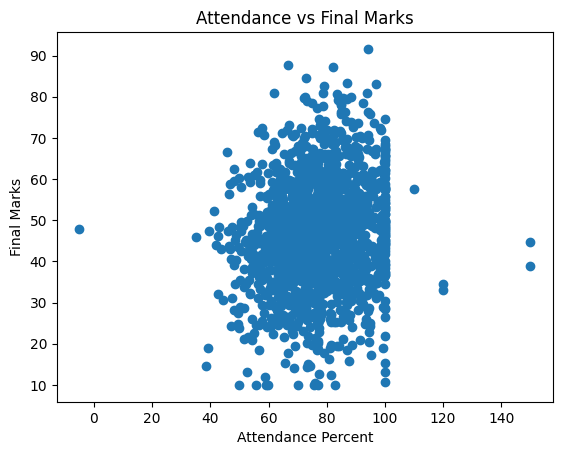

In [15]:
plt.scatter(data['Attendance_Percent'], data['Final_Marks'])
plt.xlabel('Attendance Percent')
plt.ylabel('Final Marks')
plt.title('Attendance vs Final Marks')
plt.show()

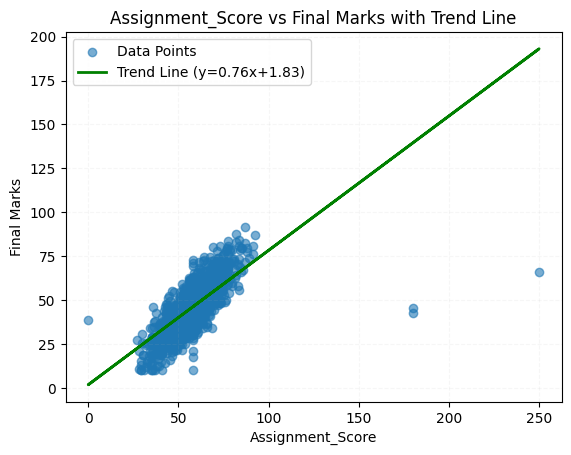

In [16]:

# Create a scatter plot
plt.scatter(data['Assignment_Score'], data['Final_Marks'], alpha=0.6, label='Data Points')

# Calculate the linear regression line (y = mx + c)
m, c = np.polyfit(data['Assignment_Score'], data['Final_Marks'], 1)

# Plot the trend line
plt.plot(data['Assignment_Score'], m*data['Assignment_Score'] + c, color='green', linewidth=2, label=f'Trend Line (y={m:.2f}x+{c:.2f})')

plt.xlabel('Assignment_Score')
plt.ylabel('Final Marks')
plt.title('Assignment_Score vs Final Marks with Trend Line')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.1)
plt.show()

In [29]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score


# Correct selection of multiple columns
X = data[['Assignment_Score', 'Quiz_Score']]
y = data['Final_Marks']


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Mean Squared Error:", mse)
print("R2 Score:", r2)

# Predict final score for a specific student with both assignment and quiz scores
test_assignmentscore = 83.9
test_quizscore = 83.6
single_input = np.array([[test_assignmentscore, test_quizscore]])

# Predict directly using unscaled raw features
predicted_score = model.predict(single_input)
print(f"Predicted final score for Assignment={test_assignmentscore}% and Quiz={test_quizscore}%:", predicted_score[0])

Mean Squared Error: 46.18624571979024
R2 Score: 0.7570557372448585
Predicted final score for Assignment=83.9% and Quiz=83.6%: 80.566


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
